# Dataset Exploration - Spotify Tracks
## Analyse complète pour le projet NoSQL Music Recommendation System

**Objectifs:**
- Comprendre la structure du dataset
- Analyser la qualité des données
- Définir le mapping Neo4j vs MongoDB
- Identifier les besoins d'enrichissement API

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


## 1. Chargement du Dataset

In [82]:
# Chemin du dataset
dataset_path = r"C:\Users\Eya\Desktop\music-graph-neo4j\data\raw\ClassicHit.csv"

# Chargement
print("Loading dataset...")
df = pd.read_csv(dataset_path)
print(f"✅ Dataset loaded: {len(df):,} rows")

# Aperçu
df.head()

Loading dataset...
✅ Dataset loaded: 15,150 rows


,Track,Artist,Year,Duration,Time_Signature,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Popularity,Genre
0,Hey Jack Kerouac,"10,000 Maniacs",1987,206413,4,0.616,0.511,6,-15.894,1,0.0279,0.03840,0.000000,0.1500,0.604,132.015,40,Alt. Rock
1,Like the Weather,"10,000 Maniacs",1987,236653,4,0.770,0.459,1,-17.453,1,0.0416,0.11200,0.003430,0.1450,0.963,133.351,43,Alt. Rock
2,What's the Matter Here?,"10,000 Maniacs",1987,291173,4,0.593,0.816,9,-7.293,1,0.0410,0.00449,0.000032,0.0896,0.519,99.978,12,Alt. Rock
3,Trouble Me,"10,000 Maniacs",1989,193560,4,0.861,0.385,2,-10.057,1,0.0341,0.15400,0.000000,0.1230,0.494,117.913,47,Alt. Rock
4,Candy Everybody Wants,"10,000 Maniacs",1992,185960,4,0.622,0.876,10,-6.310,1,0.0305,0.01930,0.006840,0.0987,0.867,104.970,43,Alt. Rock


## 2. Structure et Types de Données

In [83]:
# Informations générales
print("="*80)
print("DATASET INFORMATION")
print("="*80)
df.info()

print("\n" + "="*80)
print("SHAPE:")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\n" + "="*80)
print("COLUMN NAMES:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:2d}. {col}")

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15150 entries, 0 to 15149
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Track             15150 non-null  object 
 1   Artist            15150 non-null  object 
 2   Year              15150 non-null  int64  
 3   Duration          15150 non-null  int64  
 4   Time_Signature    15150 non-null  int64  
 5   Danceability      15150 non-null  float64
 6   Energy            15150 non-null  float64
 7   Key               15150 non-null  int64  
 8   Loudness          15150 non-null  float64
 9   Mode              15150 non-null  int64  
 10  Speechiness       15150 non-null  float64
 11  Acousticness      15150 non-null  float64
 12  Instrumentalness  15150 non-null  float64
 13  Liveness          15150 non-null  float64
 14  Valence           15150 non-null  float64
 15  Tempo             15150 non-null  float64
 16  Popularity        15

## 3. Analyse de la Qualité des Données

In [84]:
# Valeurs manquantes
print("="*80)
print("MISSING VALUES ANALYSIS")
print("="*80)

missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing_Count': missing,
    'Percentage': missing_pct
}).sort_values('Missing_Count', ascending=False)

print(missing_df[missing_df['Missing_Count'] > 0])

# Visualisation
if missing_df['Missing_Count'].sum() > 0:
    plt.figure(figsize=(12, 6))
    missing_cols = missing_df[missing_df['Missing_Count'] > 0]
    plt.barh(missing_cols.index, missing_cols['Percentage'])
    plt.xlabel('Percentage Missing (%)')
    plt.title('Missing Values by Column')
    plt.tight_layout()
    plt.show()
else:
    print("\n✅ No missing values detected!")

MISSING VALUES ANALYSIS
Empty DataFrame
Columns: [Missing_Count, Percentage]
Index: []

✅ No missing values detected!


In [85]:
# Duplicates
print("="*80)
print("DUPLICATE ANALYSIS")
print("="*80)

duplicates_all = df.duplicated().sum()
print(f"Total duplicate rows: {duplicates_all:,} ({(duplicates_all/len(df)*100):.2f}%)")

# Check for specific columns if they exist
if 'track_name' in df.columns and 'artists' in df.columns:
    duplicates_tracks = df.duplicated(subset=['track_name', 'artists']).sum()
    print(f"Duplicate track-artist combinations: {duplicates_tracks:,}")

DUPLICATE ANALYSIS
Total duplicate rows: 1 (0.01%)


## 4. Statistiques Descriptives

In [86]:
# Colonnes numériques
print("="*80)
print("NUMERICAL FEATURES STATISTICS")
print("="*80)
df.describe().T

NUMERICAL FEATURES STATISTICS


,count,mean,std,min,25%,50%,75%,max
Year,15150.0,1984.709769,19.482460,1899.000000,1971.000000,1983.000000,1998.00000,2024.000
Duration,15150.0,241302.814983,105796.634810,23000.000000,180370.000000,222852.500000,275153.00000,3060650.000
Time_Signature,15150.0,3.921650,0.348322,0.000000,4.000000,4.000000,4.00000,5.000
Danceability,15150.0,0.574667,0.166208,0.000000,0.461000,0.582000,0.69600,0.988
Energy,15150.0,0.617691,0.239527,0.000098,0.442000,0.644000,0.81900,0.999
Key,15150.0,5.257624,3.569713,0.000000,2.000000,5.000000,8.00000,11.000
Loudness,15150.0,-9.154545,4.289558,-47.359000,-11.736750,-8.480500,-5.95550,0.919
Mode,15150.0,0.696634,0.459727,0.000000,0.000000,1.000000,1.00000,1.000
Speechiness,15150.0,0.075791,0.077704,0.000000,0.034325,0.046400,0.07840,0.950
Acousticness,15150.0,0.302651,0.317793,0.000001,0.024225,0.167000,0.55700,0.996


In [87]:
# Colonnes catégorielles
print("="*80)
print("CATEGORICAL FEATURES ANALYSIS")
print("="*80)

categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    print(f"\n{col.upper()}:")
    print(f"  Unique values: {df[col].nunique():,}")
    print(f"  Top 5 most common:")
    print(df[col].value_counts().head())

CATEGORICAL FEATURES ANALYSIS

TRACK:
  Unique values: 13,771
  Top 5 most common:
Track
Lady        8
Stardust    7
Stay        7
Crazy       7
Forever     6
Name: count, dtype: int64

ARTIST:
  Unique values: 3,083
  Top 5 most common:
Artist
Elton John            54
Michael Jackson       37
Bee Gees              36
The Rolling Stones    33
Chicago               32
Name: count, dtype: int64

GENRE:
  Unique values: 19
  Top 5 most common:
Genre
Pop        3669
Metal       922
Country     833
R&B         822
Rock        799
Name: count, dtype: int64


## 5. Analyse Spécifique aux Entités du Graphe

In [88]:
# Artists Analysis
print("="*80)
print("ARTISTS ANALYSIS")
print("="*80)

if 'artists' in df.columns:
    # Unique artists
    print(f"Total unique artists: {df['artists'].nunique():,}")
    
    # Most prolific artists
    print("\nTop 10 Most Prolific Artists:")
    print(df['artists'].value_counts().head(10))
    
    # Check for multi-artist tracks (if separated by delimiter)
    if df['artists'].astype(str).str.contains(',|;|&').any():
        print("\n⚠️  Multi-artist tracks detected - will need parsing for Neo4j")
        sample_multi = df[df['artists'].astype(str).str.contains(',|;|&')]['artists'].head(5)
        print("\nSamples:")
        for artist in sample_multi:
            print(f"  - {artist}")

ARTISTS ANALYSIS


GENRES ANALYSIS

Genre:
  Unique genres: 19

  Top 10 genres:
Genre
Pop          3669
Metal         922
Country       833
R&B           822
Rock          799
Alt. Rock     780
Jazz          778
Punk          754
Rap           718
EDM           700
Name: count, dtype: int64


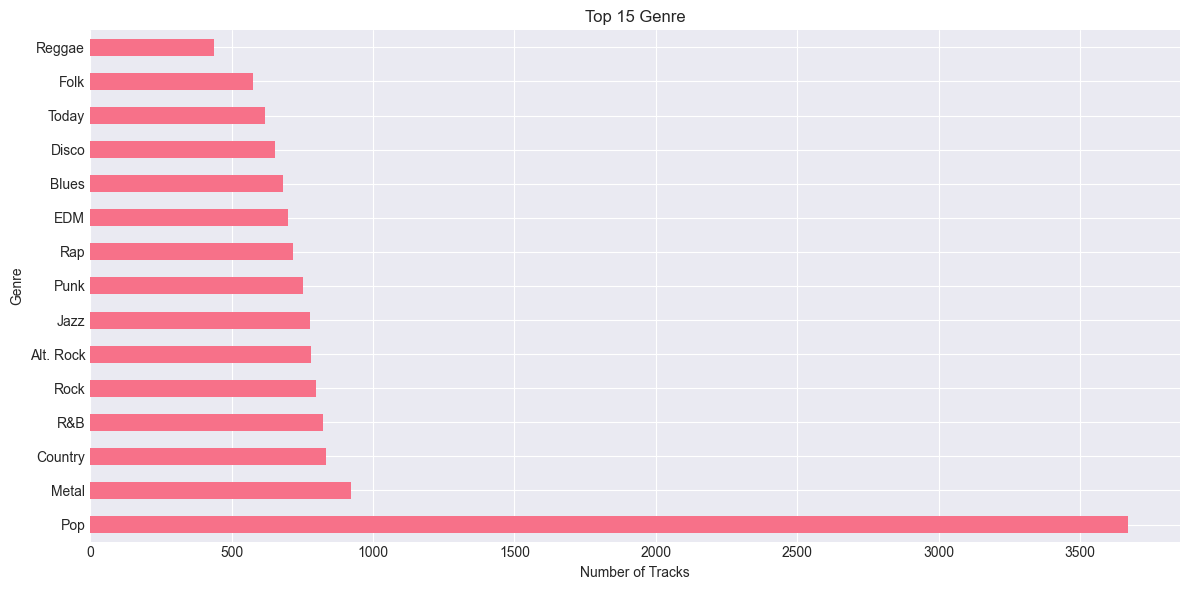

In [89]:
# Genres Analysis
print("="*80)
print("GENRES ANALYSIS")
print("="*80)

genre_cols = [col for col in df.columns if 'genre' in col.lower()]

if genre_cols:
    for col in genre_cols:
        print(f"\n{col}:")
        print(f"  Unique genres: {df[col].nunique():,}")
        print(f"\n  Top 10 genres:")
        print(df[col].value_counts().head(10))
        
        # Visualisation
        plt.figure(figsize=(12, 6))
        df[col].value_counts().head(15).plot(kind='barh')
        plt.xlabel('Number of Tracks')
        plt.title(f'Top 15 {col}')
        plt.tight_layout()
        plt.show()
else:
    print("⚠️  No genre columns found")

In [90]:
# Albums Analysis (if exists)
print("="*80)
print("ALBUMS ANALYSIS")
print("="*80)

album_cols = [col for col in df.columns if 'album' in col.lower()]

if album_cols:
    for col in album_cols:
        print(f"\n{col}:")
        print(f"  Unique albums: {df[col].nunique():,}")
        print(f"\n  Top 10 albums:")
        print(df[col].value_counts().head(10))
else:
    print("⚠️  No album columns found")

ALBUMS ANALYSIS
⚠️  No album columns found


## 6. Audio Features Analysis

In [91]:
# Identifier les audio features potentielles
print("="*80)
print("AUDIO FEATURES IDENTIFICATION")
print("="*80)

# Spotify audio features standards
spotify_features = ['danceability', 'energy', 'key', 'loudness', 'mode', 
                    'speechiness', 'acousticness', 'instrumentalness', 
                    'liveness', 'valence', 'tempo', 'duration_ms', 'time_signature']

available_features = [col for col in df.columns if any(feat in col.lower() for feat in spotify_features)]

print(f"\nAvailable audio features: {len(available_features)}")
for feat in available_features:
    print(f"  ✓ {feat}")

if not available_features:
    print("\n⚠️  No standard Spotify audio features found")
    print("Will need to enrich via Spotify API")

AUDIO FEATURES IDENTIFICATION

Available audio features: 12
  ✓ Time_Signature
  ✓ Danceability
  ✓ Energy
  ✓ Key
  ✓ Loudness
  ✓ Mode
  ✓ Speechiness
  ✓ Acousticness
  ✓ Instrumentalness
  ✓ Liveness
  ✓ Valence
  ✓ Tempo


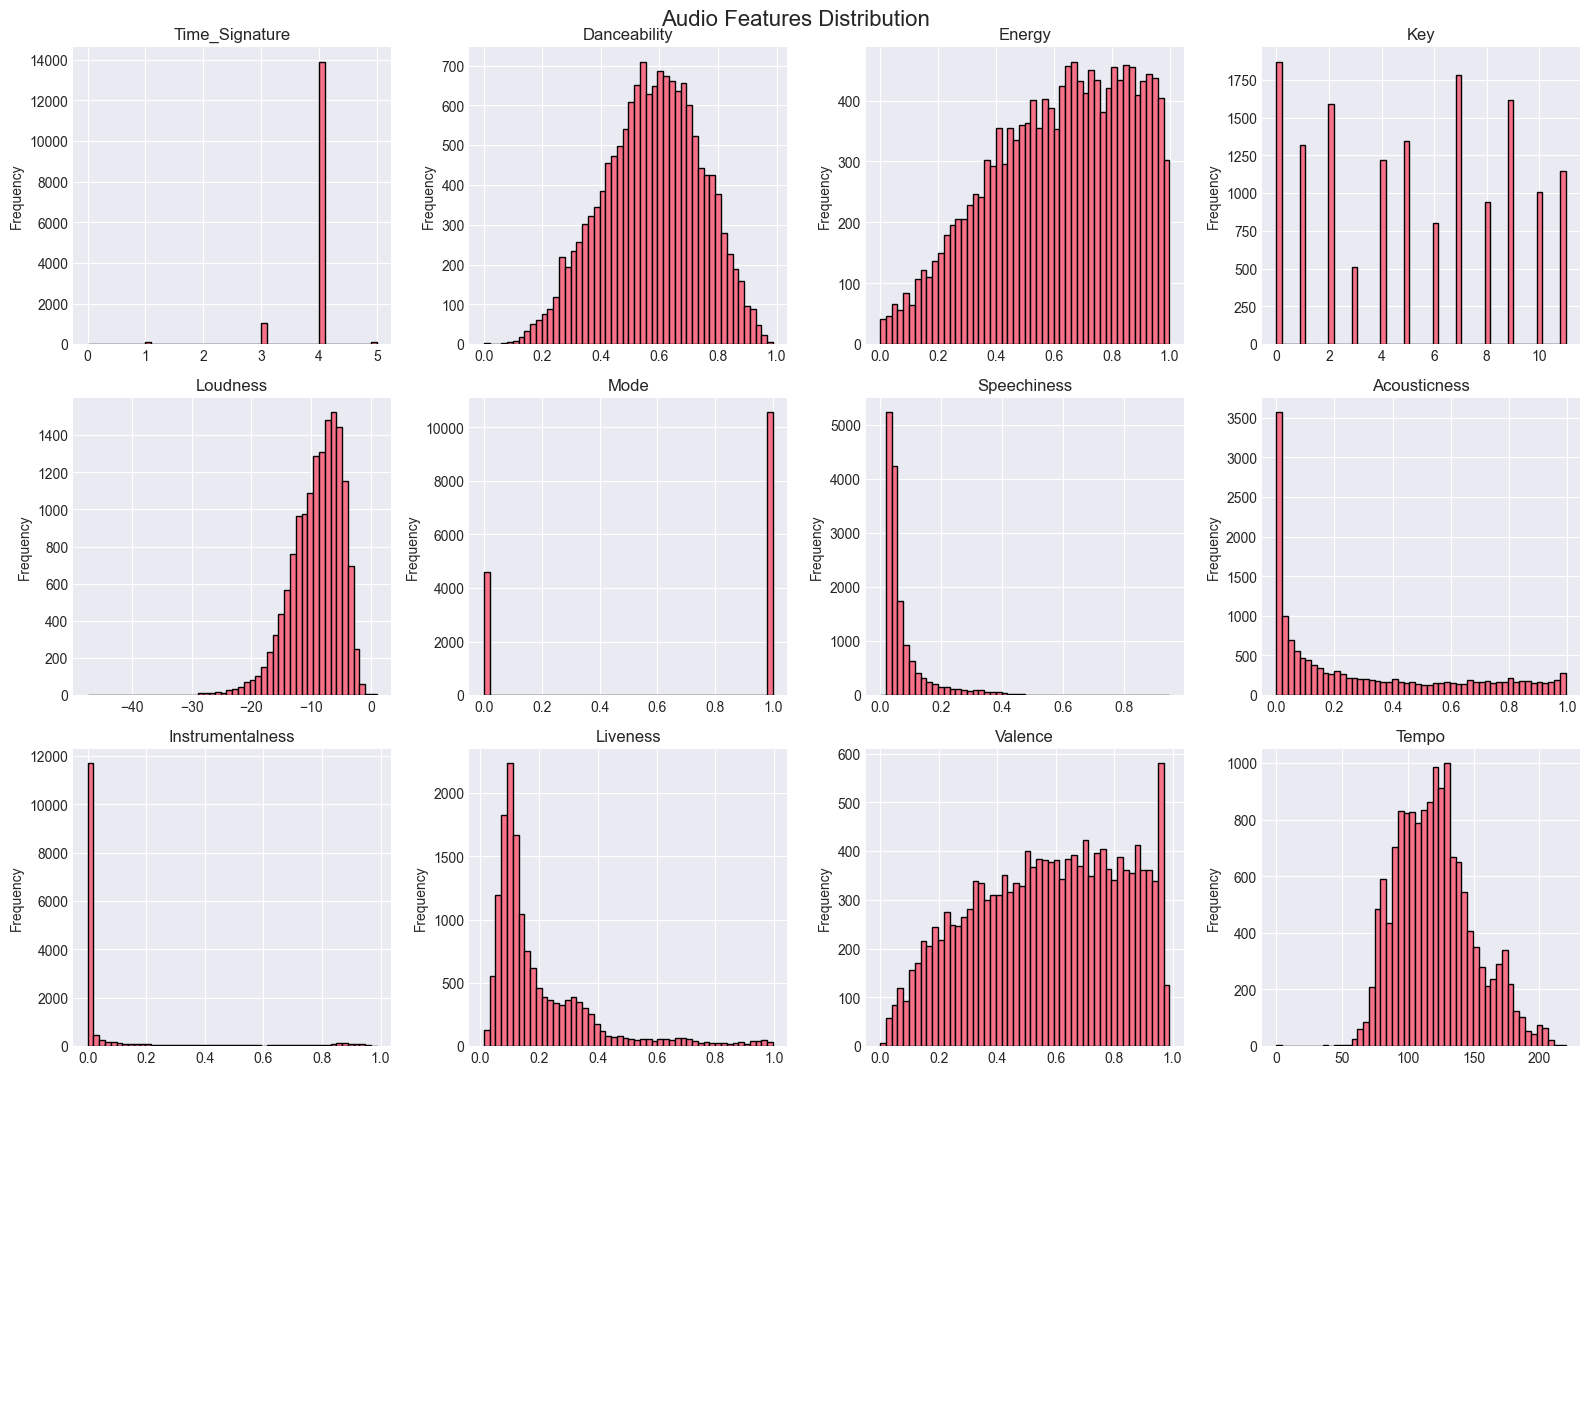

In [92]:
# Visualisation des audio features (si disponibles)
if available_features:
    # Distribution plots
    fig, axes = plt.subplots(4, 4, figsize=(16, 14))
    axes = axes.flatten()
    
    for idx, col in enumerate(available_features[:16]):
        if idx < len(axes):
            df[col].hist(bins=50, ax=axes[idx], edgecolor='black')
            axes[idx].set_title(col)
            axes[idx].set_ylabel('Frequency')
    
    # Hide unused subplots
    for idx in range(len(available_features), len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.suptitle('Audio Features Distribution', y=1.002, fontsize=16)
    plt.show()

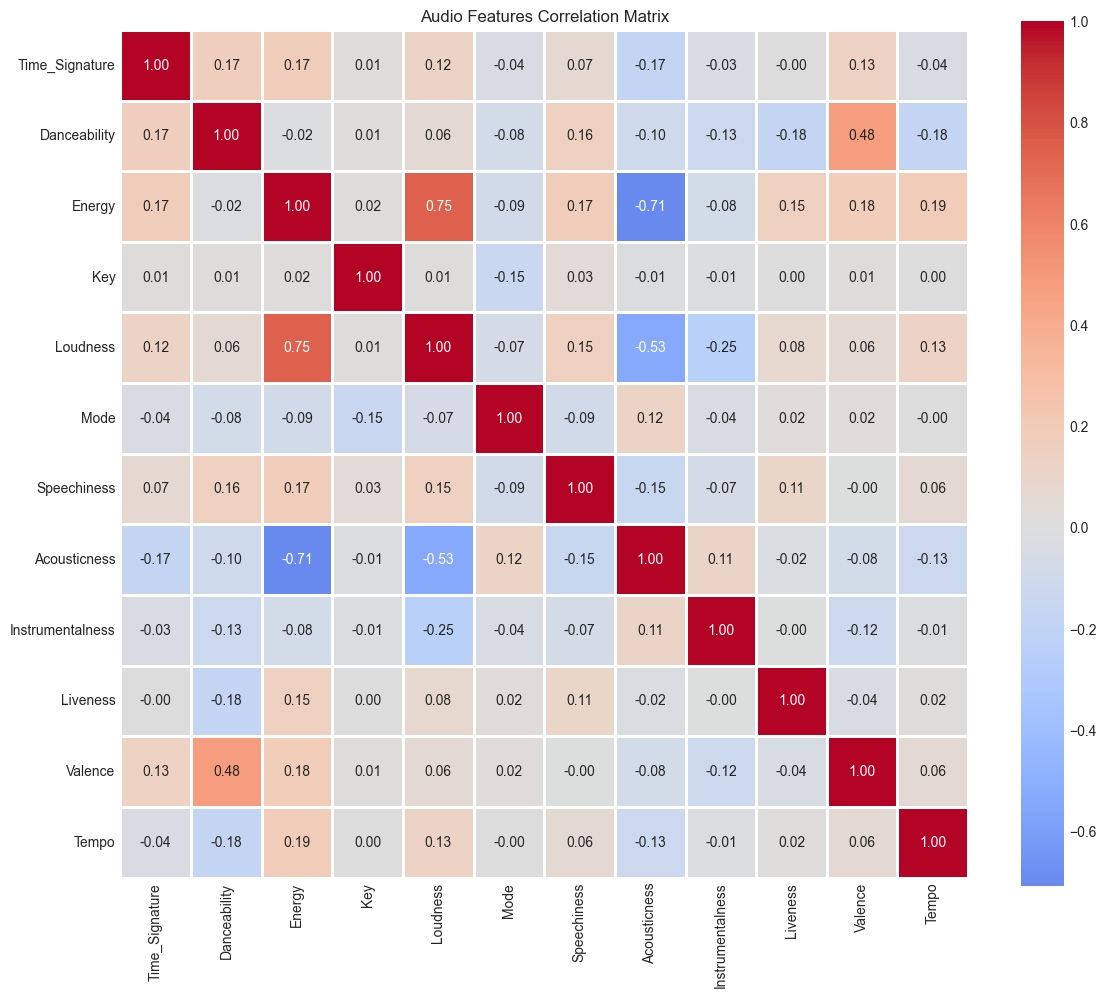

In [93]:
# Correlation entre audio features
if len(available_features) > 1:
    plt.figure(figsize=(12, 10))
    correlation_matrix = df[available_features].corr()
    sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
                center=0, square=True, linewidths=1)
    plt.title('Audio Features Correlation Matrix')
    plt.tight_layout()
    plt.show()

## 7. Popularity & Metrics Analysis

POPULARITY METRICS

Popularity:
count    15150.000000
mean        43.025809
std         20.788038
min          0.000000
25%         28.000000
50%         44.000000
75%         59.000000
max         98.000000
Name: Popularity, dtype: float64


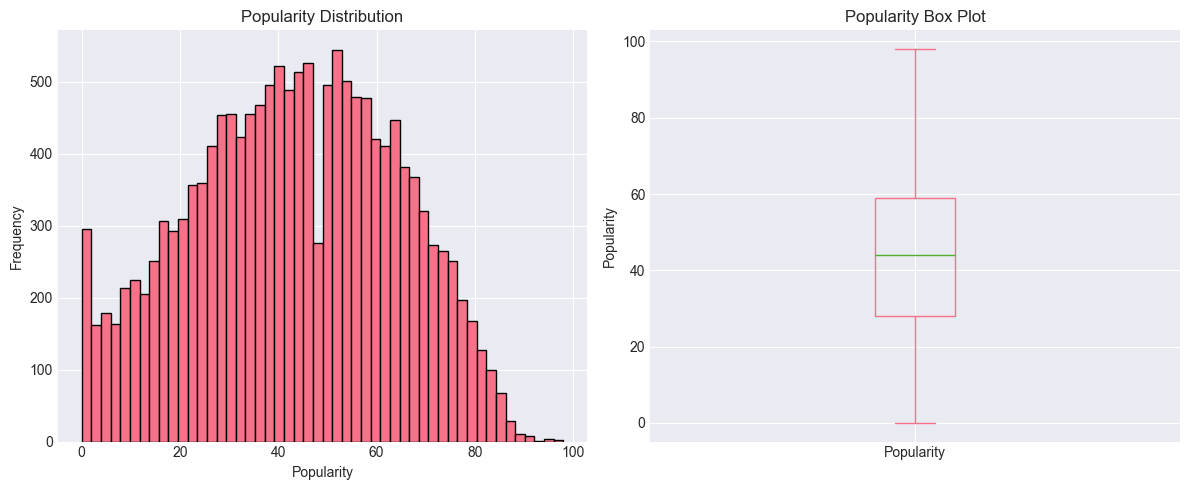

In [94]:
# Popularity analysis
print("="*80)
print("POPULARITY METRICS")
print("="*80)

popularity_cols = [col for col in df.columns if 'popularity' in col.lower() or 'play' in col.lower()]

if popularity_cols:
    for col in popularity_cols:
        print(f"\n{col}:")
        print(df[col].describe())
        
        plt.figure(figsize=(12, 5))
        
        plt.subplot(1, 2, 1)
        df[col].hist(bins=50, edgecolor='black')
        plt.xlabel(col)
        plt.ylabel('Frequency')
        plt.title(f'{col} Distribution')
        
        plt.subplot(1, 2, 2)
        df[col].plot(kind='box')
        plt.ylabel(col)
        plt.title(f'{col} Box Plot')
        
        plt.tight_layout()
        plt.show()
else:
    print("⚠️  No popularity columns found")

## 8. Temporal Data Analysis

In [95]:
# Date columns
print("="*80)
print("TEMPORAL DATA ANALYSIS")
print("="*80)

date_cols = [col for col in df.columns if any(term in col.lower() for term in ['date', 'year', 'release'])]

if date_cols:
    print(f"\nFound {len(date_cols)} temporal columns:")
    for col in date_cols:
        print(f"  ✓ {col}")
        print(f"    - Type: {df[col].dtype}")
        print(f"    - Sample values: {df[col].dropna().head(3).tolist()}")
        print(f"    - Missing: {df[col].isnull().sum():,} ({df[col].isnull().sum()/len(df)*100:.1f}%)")
else:
    print("\n❌ NO TEMPORAL DATA FOUND")
    print("\n📌 RECOMMENDATION: Enrich with release dates via Spotify API")
    print("   This will enable:")
    print("   - Trend analysis over time")
    print("   - Era-based recommendations")
    print("   - Temporal popularity patterns")

TEMPORAL DATA ANALYSIS

Found 1 temporal columns:
  ✓ Year
    - Type: int64
    - Sample values: [1987, 1987, 1987]
    - Missing: 0 (0.0%)


## 9. Data Mapping Strategy: Neo4j vs MongoDB

In [96]:
print("="*80)
print("DATA MAPPING STRATEGY")
print("="*80)

# Automatically categorize columns
neo4j_candidates = []
mongodb_candidates = []

# Neo4j: Entities and relationships
neo4j_keywords = ['id', 'name', 'artist', 'album', 'genre', 'track']
for col in df.columns:
    if any(keyword in col.lower() for keyword in neo4j_keywords):
        neo4j_candidates.append(col)

# MongoDB: Audio features, metadata, metrics
mongodb_keywords = spotify_features + ['popularity', 'explicit', 'duration']
for col in df.columns:
    if any(keyword in col.lower() for keyword in mongodb_keywords):
        if col not in neo4j_candidates:
            mongodb_candidates.append(col)

print("\n📊 NEO4J - Graph Structure (Nodes & Relationships):")
print(f"   Total columns: {len(neo4j_candidates)}")
for col in neo4j_candidates:
    print(f"   ✓ {col}")

print("\n📦 MONGODB - Document Store (Audio Features & Metadata):")
print(f"   Total columns: {len(mongodb_candidates)}")
for col in mongodb_candidates:
    print(f"   ✓ {col}")

print("\n🔗 COMMON IDENTIFIER:")
id_cols = [col for col in df.columns if 'id' in col.lower()]
if id_cols:
    print(f"   Use '{id_cols[0]}' to link Neo4j ↔ MongoDB")
else:
    print("   ⚠️  Need to create unique IDs for linking")

DATA MAPPING STRATEGY

📊 NEO4J - Graph Structure (Nodes & Relationships):
   Total columns: 3
   ✓ Track
   ✓ Artist
   ✓ Genre

📦 MONGODB - Document Store (Audio Features & Metadata):
   Total columns: 14
   ✓ Duration
   ✓ Time_Signature
   ✓ Danceability
   ✓ Energy
   ✓ Key
   ✓ Loudness
   ✓ Mode
   ✓ Speechiness
   ✓ Acousticness
   ✓ Instrumentalness
   ✓ Liveness
   ✓ Valence
   ✓ Tempo
   ✓ Popularity

🔗 COMMON IDENTIFIER:
   ⚠️  Need to create unique IDs for linking


## 10. Data Quality Issues & Recommendations

In [97]:
print("="*80)
print("DATA QUALITY SUMMARY & RECOMMENDATIONS")
print("="*80)

issues = []
recommendations = []

# Check for missing critical fields
critical_fields = ['track_name', 'artists', 'track_id', 'id']
existing_critical = [f for f in critical_fields if f in df.columns]
missing_critical = [f for f in critical_fields if f not in df.columns]

if missing_critical:
    issues.append(f"Missing critical fields: {', '.join(missing_critical)}")

# Check for temporal data
if not date_cols:
    issues.append("No temporal data (release dates)")
    recommendations.append("Enrich with Spotify API for release_date")

# Check for audio features
if len(available_features) < 5:
    issues.append(f"Limited audio features ({len(available_features)} found)")
    recommendations.append("Consider enriching with Spotify Audio Features API")

# Check data size
dataset_size = len(df)
if dataset_size > 100000:
    recommendations.append(f"Dataset size ({dataset_size:,}) is good for 4-day project")
else:
    issues.append(f"Dataset might be too small ({dataset_size:,} tracks)")

print("\n⚠️  ISSUES IDENTIFIED:")
if issues:
    for i, issue in enumerate(issues, 1):
        print(f"   {i}. {issue}")
else:
    print("   ✅ No critical issues found!")

print("\n💡 RECOMMENDATIONS:")
if recommendations:
    for i, rec in enumerate(recommendations, 1):
        print(f"   {i}. {rec}")
else:
    print("   ✅ Dataset is ready to use!")

print("\n" + "="*80)
print("FINAL VERDICT")
print("="*80)
print(f"✅ Dataset has {len(df):,} tracks")
print(f"✅ {len(existing_critical)} critical fields present")
print(f"✅ {len(available_features)} audio features available")
print(f"✅ {df['artists'].nunique() if 'artists' in df.columns else 'N/A'} unique artists")
print("\n🎯 DATASET IS READY FOR THE PROJECT!")
print("   Next steps: Data preprocessing → Neo4j import → MongoDB setup")

DATA QUALITY SUMMARY & RECOMMENDATIONS

⚠️  ISSUES IDENTIFIED:
   1. Missing critical fields: track_name, artists, track_id, id
   2. Dataset might be too small (15,150 tracks)

💡 RECOMMENDATIONS:
   ✅ Dataset is ready to use!

FINAL VERDICT
✅ Dataset has 15,150 tracks
✅ 0 critical fields present
✅ 12 audio features available
✅ N/A unique artists

🎯 DATASET IS READY FOR THE PROJECT!
   Next steps: Data preprocessing → Neo4j import → MongoDB setup


## 11. Export Summary Report

In [98]:
# Create summary dictionary
summary = {
    'total_tracks': len(df),
    'total_columns': len(df.columns),
    'unique_artists': df['artists'].nunique() if 'artists' in df.columns else None,
    'audio_features': available_features,
    'neo4j_columns': neo4j_candidates,
    'mongodb_columns': mongodb_candidates,
    'has_temporal_data': len(date_cols) > 0,
    'missing_values_pct': (df.isnull().sum().sum() / (len(df) * len(df.columns))) * 100,
    'duplicates': df.duplicated().sum()
}

print("\n📊 SUMMARY REPORT:")
for key, value in summary.items():
    if isinstance(value, list):
        print(f"\n{key}: {len(value)} items")
        for item in value[:5]:  # Show first 5
            print(f"  - {item}")
        if len(value) > 5:
            print(f"  ... and {len(value)-5} more")
    else:
        print(f"{key}: {value}")

print("\n✅ Exploration complete!")


📊 SUMMARY REPORT:
total_tracks: 15150
total_columns: 18
unique_artists: None

audio_features: 12 items
  - Time_Signature
  - Danceability
  - Energy
  - Key
  - Loudness
  ... and 7 more

neo4j_columns: 3 items
  - Track
  - Artist
  - Genre

mongodb_columns: 14 items
  - Duration
  - Time_Signature
  - Danceability
  - Energy
  - Key
  ... and 9 more
has_temporal_data: True
missing_values_pct: 0.0
duplicates: 1

✅ Exploration complete!
